# Task 3: Monthly Spending Prediction (regression)
Target `spending_30d` (THB over the next 30 days)

**Pipeline:** load → audit → EDA → repair the missing values with exact row identities → two-stage hurdle model (will they spend? how much relative to history?) → median read-out → write `task3` into the submission

The competition metric is **NMAE = 1 / (1 + Σ|y−ŷ| / Σy)**: higher is better, and it only depends on the absolute error, so the prediction should be the conditional **median**, which is exactly 0 for anyone who is more likely than not to spend nothing.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, lightgbm as lgb
from scipy.stats import norm
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

import os, glob
# Data: this folder locally; on Kaggle the competition's 03_regression folder (searched for if mounted elsewhere)
KAGGLE_DIR = '/kaggle/input/competitions/player-intelligence-system-cpe-342-ml/cpe342-kaggle-main'
ON_KAGGLE = os.path.exists('/kaggle/input')
if ON_KAGGLE:
    DATA_DIR = f'{KAGGLE_DIR}/03_regression'
    if not os.path.exists(f'{DATA_DIR}/test.csv'):
        DATA_DIR = os.path.dirname(glob.glob('/kaggle/input/**/03_regression/test.csv', recursive=True)[0])
else:
    DATA_DIR = '.'
OUT_DIR = '/kaggle/working' if ON_KAGGLE else '.'
print('data from:', os.path.abspath(DATA_DIR))
TARGET, ID = 'spending_30d', 'player_id'
sns.set_theme(style='whitegrid')
train = pd.read_csv(f'{DATA_DIR}/train.csv'); test = pd.read_csv(f'{DATA_DIR}/test.csv')
FEATS = [c for c in test.columns if c != ID]
y = train[TARGET].values
Y_MAX = y.max()   # target is capped (300,000 THB)
nmae = lambda y, p: 1 / (1 + np.abs(y - p).sum() / y.sum())
print(train.shape, test.shape, len(FEATS), 'features')

data from: /kaggle/input/competitions/player-intelligence-system-cpe-342-ml/cpe342-kaggle-main/03_regression
(104000, 34) (25889, 33) 32 features


## 1. Audit

In [2]:
print('target NaN:', np.isnan(y).sum(), '| share of zeros:', (y == 0).mean().round(3), '| max:', Y_MAX, '(rows at max:', (y == Y_MAX).sum(), ')')
print('percentiles (25/50/75/95/99):', np.percentile(y, [25, 50, 75, 95, 99]).round(0))
print('duplicate ids:', train[ID].duplicated().sum(), '| train/test id overlap:', train[ID].isin(test[ID]).sum())
print('missing share median (train):', round(float(train[FEATS].isna().mean().median()), 3))

target NaN: 0 | share of zeros: 0.481 | max: 300000.0 (rows at max: 15 )
percentiles (25/50/75/95/99): [0.00000e+00 7.90000e+01 2.46100e+03 7.59700e+04 1.50032e+05]
duplicate ids: 0 | train/test id overlap: 0
missing share median (train): 0.058


## 2. EDA

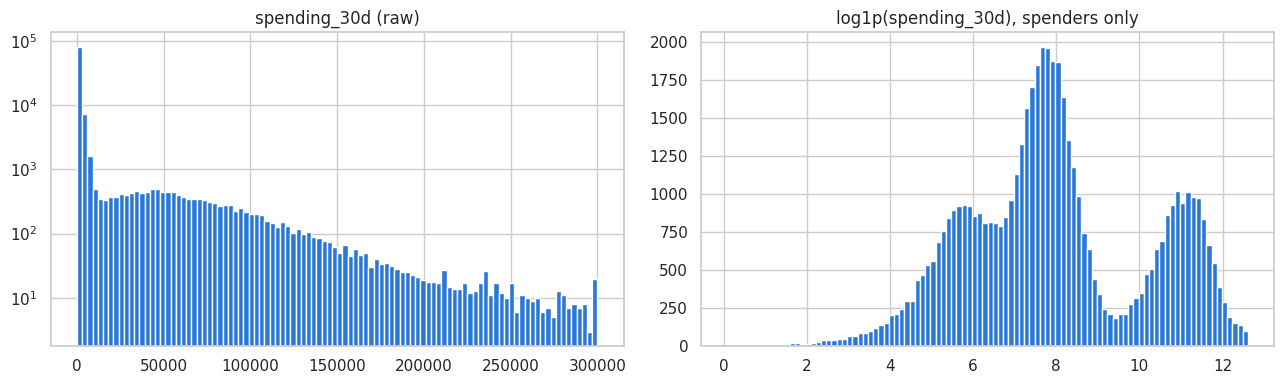

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(y, bins=100, color='#2a78d6'); axes[0].set(title='spending_30d (raw)', yscale='log')
axes[1].hist(np.log1p(y[y > 0]), bins=100, color='#2a78d6'); axes[1].set(title='log1p(spending_30d), spenders only')
plt.tight_layout(); plt.show()

top |corr| with target:
historical_spending         0.867
prev_month_spending         0.865
segment                     0.567
event_participation_rate    0.498
vip_status                  0.443
is_premium_member           0.414
total_transactions          0.284
avg_transaction_value       0.266
purchases_on_discount       0.246
owns_limited_edition        0.201

spenders only: corr(log y, log prev_month) = 0.9815
historical / prev_month ratio (5/50/95%): [2.52, 2.86, 3.3]
zero rate by segment: {0.0: 0.724, 1.0: 0.48, 2.0: 0.306, 3.0: 0.071}


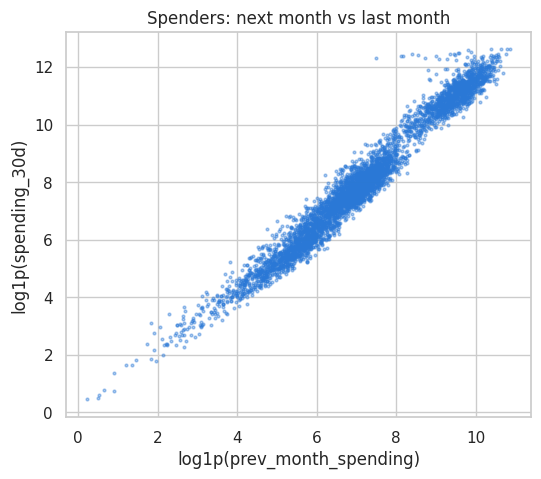

In [4]:
corr = train[FEATS + [TARGET]].corr()[TARGET].drop(TARGET).abs().sort_values(ascending=False)
print('top |corr| with target:'); print(corr.head(10).round(3).to_string())

pos = y > 0
k = pos & train.prev_month_spending.notna()
print('\nspenders only: corr(log y, log prev_month) =', np.corrcoef(np.log1p(y[k]), np.log1p(train.prev_month_spending[k]))[0, 1].round(4))
print('historical / prev_month ratio (5/50/95%):', (train.historical_spending / train.prev_month_spending).quantile([.05, .5, .95]).round(2).tolist())
print('zero rate by segment:', train.groupby('segment')[TARGET].apply(lambda s: (s == 0).mean()).round(3).to_dict())

fig, ax = plt.subplots(figsize=(6, 5))
s = train[k].sample(5000, random_state=0)
ax.scatter(np.log1p(s.prev_month_spending), np.log1p(s[TARGET]), s=4, alpha=.4, color='#2a78d6')
ax.set(xlabel='log1p(prev_month_spending)', ylabel='log1p(spending_30d)', title='Spenders: next month vs last month'); plt.show()

### Key insights
1. **48% of players spend 0**, and the rest have a heavy tail (skew 4.2, capped at 300,000). The metric changes which model is best: RMSE is dominated by the big spenders, MAE by the median, RMSLE by the zeros.
2. **For players who do spend, the amount is almost a function of past spending:** corr(log y, log `prev_month_spending`) ≈ **0.98**, and `historical_spending` is about 2.9 × `prev_month_spending` for nearly everyone.
3. **The hard part is whether a player spends at all** (classifier AUC ≈ 0.78). `segment` matters a lot here: 72% of Casuals spend 0 against 7% of Whales.
4. **Exact identities inside each row** (checked in section 3): `historical_spending = total_transactions × avg_transaction_value` (and `= avg_transaction_value` when there were 0 transactions), `purchases_on_discount = total_transactions × discount_rate_used`, and the ratio of last month's spend to historical spend is never outside 0.30–0.40. About 5.8% of each column is missing at random, so most of the gaps can be filled exactly.
5. So a **hurdle model** fits naturally: P(spend > 0), and for spenders the amount *relative to their history*.

## 3. Repair the missing values

In [5]:
# identities hold exactly: check them on the complete rows
ok = train[['historical_spending', 'total_transactions', 'avg_transaction_value']].dropna()
prod = ok.total_transactions * ok.avg_transaction_value
holds = ((ok.historical_spending - prod).abs() <= 1e-6 * ok.historical_spending.abs().clip(lower=1e-9)) | ((ok.total_transactions == 0) & (ok.historical_spending == ok.avg_transaction_value))
print(f'hist = txn x avg (or = avg when txn = 0) holds on {holds.mean():.4f} of complete rows')
ratio = (train.prev_month_spending / train.historical_spending).median()
print('prev / hist: median', round(ratio, 3), '| 1%-99% range', (train.prev_month_spending / train.historical_spending).quantile([.01, .99]).round(3).tolist())

def repair(d):
    d = d.copy(); S = lambda v: pd.Series(np.asarray(v, float), index=d.index)
    fill = lambda col, v: d.__setitem__(col, d[col].fillna(S(v)))
    h, t, a = d.historical_spending, d.total_transactions, d.avg_transaction_value
    fill('historical_spending', np.where(t == 0, a, t * a))
    h = d.historical_spending
    fill('total_transactions', np.where(a > 0, np.round(h / a.where(a > 0)), 0))
    t = d.total_transactions
    fill('avg_transaction_value', np.where(t > 0, h / t.where(t > 0), h))
    fill('historical_spending', d.prev_month_spending / ratio)       # approximate: the ratio is in 0.30-0.40
    fill('prev_month_spending', d.historical_spending * ratio)
    p, r = d.purchases_on_discount, d.discount_rate_used
    fill('purchases_on_discount', d.total_transactions * r)
    fill('discount_rate_used', p / d.total_transactions.where(d.total_transactions > 0))
    return d

Xtr, Xte = repair(train[FEATS]), repair(test[FEATS])
ID_COLS = ['historical_spending', 'prev_month_spending', 'total_transactions', 'avg_transaction_value', 'purchases_on_discount', 'discount_rate_used']
print('still missing after repair (train rows):', Xtr[ID_COLS].isna().sum().to_dict())

# segment is fully determined by other columns: a classifier trained on rows that have it fills the missing ones
seg_feats = [c for c in FEATS if c != 'segment']
known = Xtr.segment.notna()
seg_clf = lgb.LGBMClassifier(n_estimators=300, learning_rate=.1, verbose=-1).fit(Xtr.loc[known, seg_feats], Xtr.loc[known, 'segment'].astype(int))
for D in (Xtr, Xte):
    m = D.segment.isna(); D['segment_imputed'] = m.astype(int)
    if m.any(): D.loc[m, 'segment'] = seg_clf.predict(D.loc[m, seg_feats])
    D['log_hist'] = np.log1p(D.historical_spending); D['log_prev'] = np.log1p(D.prev_month_spending); D['mon'] = (D.log_hist + D.log_prev) / 2
print('segment filled:', int(Xtr.segment_imputed.sum()), 'train /', int(Xte.segment_imputed.sum()), 'test rows')

hist = txn x avg (or = avg when txn = 0) holds on 1.0000 of complete rows
prev / hist: median 0.35 | 1%-99% range [0.299, 0.401]
still missing after repair (train rows): {'historical_spending': 40, 'prev_month_spending': 40, 'total_transactions': 331, 'avg_transaction_value': 350, 'purchases_on_discount': 346, 'discount_rate_used': 430}
segment filled: 5935 train / 1539 test rows


## 4. Models and metric
5-fold CV, stratified on zero / spending decile. Everything below is scored out-of-fold with the exact NMAE.

| model | OOF NMAE |
|---|---|
| L1 LightGBM on the raw table (NaNs left to the trees) | 0.7829 |
| L1 LightGBM on the repaired table | 0.7869 |
| + zero gate (predict 0 when P(spend) ≤ 0.5) | 0.7871 |
| Hurdle with ratio target, mixture-median read-out | 0.7930 |
| + Optuna-tuned LightGBM for each stage | 0.7935 |
| **+ CatBoost in both stages, averaged 50/50 with LightGBM** | **0.7938** |

The hurdle model: stage 1 is a classifier for P(y > 0). Stage 2, fitted on spenders only, predicts the **log of spend relative to history**, log1p(y) − log1p(historical_spending), with an L1 objective. This is much easier to learn than the raw amount: a spender's next-month spend stays close to a fixed multiple of what they spent before. The read-out is the median of the mixture: ŷ = 0 if p ≤ 0.5, otherwise exp(μ + σ·Φ⁻¹(1 − 0.5/p)) − 1, with σ tuned on the out-of-fold predictions. Each stage averages LightGBM and CatBoost with fixed equal weights (not tuned): the two tree learners make different errors, and the average improved every one of the 5 folds.

In [6]:
bins = pd.qcut(pd.Series(y).rank(method='first'), 10, labels=False).where(y > 0, -1)
folds = list(StratifiedKFold(5, shuffle=True, random_state=42).split(Xtr, bins))
P = dict(n_estimators=4000, learning_rate=.05, num_leaves=31, min_child_samples=40, subsample=.8, subsample_freq=1,
         colsample_bytree=.7, reg_lambda=2, verbose=-1)

def cv(make, target, rows=None, proba=False):
    # rows: training-row mask (stage 2 trains and early-stops on spenders only); returns OOF and fold-averaged test predictions
    oof, tst = np.zeros(len(Xtr)), np.zeros(len(Xte))
    for a, b in folds:
        fa = a if rows is None else a[rows[a]]; fb = b if rows is None else b[rows[b]]
        m = make().fit(Xtr.iloc[fa], target[fa], eval_set=[(Xtr.iloc[fb], target[fb])], callbacks=[lgb.early_stopping(100, verbose=False)])
        f = (lambda Z: m.predict_proba(Z)[:, 1]) if proba else m.predict
        oof[b] = f(Xtr.iloc[b]); tst += f(Xte) / len(folds)
    return oof, tst

spend = y > 0
oof_l1, _ = cv(lambda: lgb.LGBMRegressor(**P, objective='l1'), y)
print('L1 on repaired table:        OOF NMAE', round(nmae(y, np.clip(oof_l1, 0, None)), 5))

L1 on repaired table:        OOF NMAE 0.78685


### Hyperparameter tuning (Optuna)
Each hurdle stage gets its own LightGBM parameters, searched with Optuna's TPE sampler on 3 of the 5 folds: **stage 1** is scored by log-loss of P(spend > 0), **stage 2** by the mean absolute error of the log ratio on spenders (the quantity its L1 objective minimises). Trial 0 is the hand-set parameters, so a tuned set is only used if it beats them.

In [7]:
import os, json, optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
TUNE_KEYS = ('num_leaves', 'min_child_samples', 'colsample_bytree', 'subsample', 'reg_lambda', 'reg_alpha')
SPACE = lambda t: dict(num_leaves=t.suggest_int('num_leaves', 15, 127, log=True),
                       min_child_samples=t.suggest_int('min_child_samples', 10, 200, log=True),
                       colsample_bytree=t.suggest_float('colsample_bytree', .3, 1.),
                       subsample=t.suggest_float('subsample', .5, 1.),
                       reg_lambda=t.suggest_float('reg_lambda', 1e-3, 30, log=True),
                       reg_alpha=t.suggest_float('reg_alpha', 1e-3, 10, log=True))

def tune(name, score, hand, n_trials=40, timeout=20 * 60):
    # Optuna TPE search of LightGBM tree parameters (higher score = better). Trial 0 is the hand-set values,
    # so the result is never worse on this CV. Saved to <name>.json and reused on later runs (delete it to search again).
    path = f'{name}.json'
    if not os.path.exists(path):   # on Kaggle: saved parameters attached as a dataset
        path = next(iter(glob.glob(f'/kaggle/input/**/{name}.json', recursive=True)), path)
    if os.path.exists(path):
        r = json.load(open(path))
        print(f"{name}: loaded {path} | hand-set {r['hand_score']:.5f} -> best {r['best_score']:.5f} after {r['trials']} trials")
        return {**hand, **r['params']}
    start = {k: hand.get(k, 1e-3) for k in TUNE_KEYS}
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42, multivariate=True))
    study.enqueue_trial(start)
    study.optimize(lambda t: score({**hand, **SPACE(t)}), n_trials=n_trials, timeout=timeout)
    h, b = study.trials[0].value, study.best_value
    params = study.best_params if b > h else start
    json.dump({'params': params, 'hand_score': h, 'best_score': b, 'trials': len(study.trials)}, open(path, 'w'), indent=1)
    print(f'{name}: {len(study.trials)} trials | hand-set {h:.5f} -> best {b:.5f} ({b - h:+.5f})',
          '| tuned parameters used' if b > h else '| hand-set parameters kept')
    print('   chosen:', pd.Series(params, dtype=object).to_string().replace(chr(10), ' | '))
    return {**hand, **params}
from sklearn.metrics import log_loss

base = lambda D: np.log1p(np.where(D.historical_spending.isna(), D.prev_month_spending / ratio, D.historical_spending))
lb_tr = base(Xtr); fill_lb = np.nanmedian(lb_tr)
lb_tr = np.where(np.isnan(lb_tr), fill_lb, lb_tr); lb_te = base(Xte); lb_te = np.where(np.isnan(lb_te), fill_lb, lb_te)
ratio_t = np.log1p(y) - lb_tr

def score_s1(params):
    t, p = [], []
    for a, b in folds[:3]:
        m = lgb.LGBMClassifier(**params).fit(Xtr.iloc[a], spend[a].astype(int), eval_set=[(Xtr.iloc[b], spend[b].astype(int))],
                                             callbacks=[lgb.early_stopping(100, verbose=False)])
        t.append(spend[b]); p.append(m.predict_proba(Xtr.iloc[b])[:, 1])
    return -log_loss(np.concatenate(t), np.concatenate(p))

def score_s2(params):
    err = []
    for a, b in folds[:3]:
        a, b = a[spend[a]], b[spend[b]]
        m = lgb.LGBMRegressor(**params, objective='l1').fit(Xtr.iloc[a], ratio_t[a], eval_set=[(Xtr.iloc[b], ratio_t[b])],
                                                            callbacks=[lgb.early_stopping(100, verbose=False)])
        err.append(np.abs(ratio_t[b] - m.predict(Xtr.iloc[b])))
    return -np.concatenate(err).mean()

P1 = tune('task3_stage1_params', score_s1, P)
P2 = tune('task3_stage2_params', score_s2, P)

task3_stage1_params: 40 trials | hand-set -0.55361 -> best -0.55285 (+0.00076) | tuned parameters used
   chosen: num_leaves                 15 | min_child_samples         164 | colsample_bytree     0.975001 | subsample            0.920944 | reg_lambda           0.024255 | reg_alpha            2.200441
task3_stage2_params: 40 trials | hand-set -0.13699 -> best -0.13643 (+0.00056) | tuned parameters used
   chosen: num_leaves                 15 | min_child_samples         142 | colsample_bytree     0.694855 | subsample            0.959331 | reg_lambda           0.007514 | reg_alpha            0.909905


In [8]:
p_oof, p_te = cv(lambda: lgb.LGBMClassifier(**P1), spend.astype(int), proba=True)
print('stage 1 P(spend > 0): AUC', round(roc_auc_score(spend, p_oof), 4))

r_oof, r_te = cv(lambda: lgb.LGBMRegressor(**P2, objective='l1'), ratio_t, rows=spend)

# second learner for both stages: CatBoost (CPU), same folds, averaged 50/50 with LightGBM
from catboost import CatBoostClassifier, CatBoostRegressor
Xc, Xct = Xtr.astype(float), Xte.astype(float)
def cv_cat(make, target, rows=None, proba=False):
    oof, tst = np.zeros(len(Xc)), np.zeros(len(Xct))
    for a, b in folds:
        fa = a if rows is None else a[rows[a]]; fb = b if rows is None else b[rows[b]]
        m = make().fit(Xc.iloc[fa], target[fa], eval_set=(Xc.iloc[fb], target[fb]), early_stopping_rounds=200, verbose=0)
        f = (lambda Z: m.predict_proba(Z)[:, 1]) if proba else m.predict
        oof[b] = f(Xc.iloc[b]); tst += f(Xct) / len(folds)
    return oof, tst
pc_oof, pc_te = cv_cat(lambda: CatBoostClassifier(iterations=3000, learning_rate=.06, depth=6, random_seed=0),
                       spend.astype(int), proba=True)
rc_oof, rc_te = cv_cat(lambda: CatBoostRegressor(iterations=4000, learning_rate=.06, depth=6, loss_function='MAE', random_seed=0),
                       ratio_t, rows=spend)
print('stage 1 AUC  LightGBM', round(roc_auc_score(spend, p_oof), 4), '| CatBoost', round(roc_auc_score(spend, pc_oof), 4))
print('stage 2 MAE  LightGBM', round(np.abs(ratio_t - r_oof)[spend].mean(), 5), '| CatBoost', round(np.abs(ratio_t - rc_oof)[spend].mean(), 5),
      '| average', round(np.abs(ratio_t - (r_oof + rc_oof) / 2)[spend].mean(), 5))
p_oof, p_te = (p_oof + pc_oof) / 2, (p_te + pc_te) / 2
r_oof, r_te = (r_oof + rc_oof) / 2, (r_te + rc_te) / 2
mu_oof, mu_te = lb_tr + r_oof, lb_te + r_te

def readout(p, mu, sigma):
    z = np.clip(1 - .5 / np.clip(p, 1e-6, 1), 1e-6, 1 - 1e-6)
    return np.clip(np.where(p > .5, np.expm1(mu + sigma * norm.ppf(z)), 0), 0, Y_MAX)

sigmas = np.linspace(0, .4, 41)
scores = [nmae(y, readout(p_oof, mu_oof, s)) for s in sigmas]
SIGMA = float(sigmas[int(np.argmax(scores))])
oof = readout(p_oof, mu_oof, SIGMA); pred = readout(p_te, mu_te, SIGMA)
print(f'hurdle (sigma={SIGMA:.2f}): OOF NMAE {nmae(y, oof):.5f}  MAE {np.abs(y - oof).mean():,.1f}')

stage 1 P(spend > 0): AUC 0.7849
stage 1 AUC  LightGBM 0.7849 | CatBoost 0.785
stage 2 MAE  LightGBM 0.13703 | CatBoost 0.13637 | average 0.13604
hurdle (sigma=0.16): OOF NMAE 0.79385  MAE 2,726.0


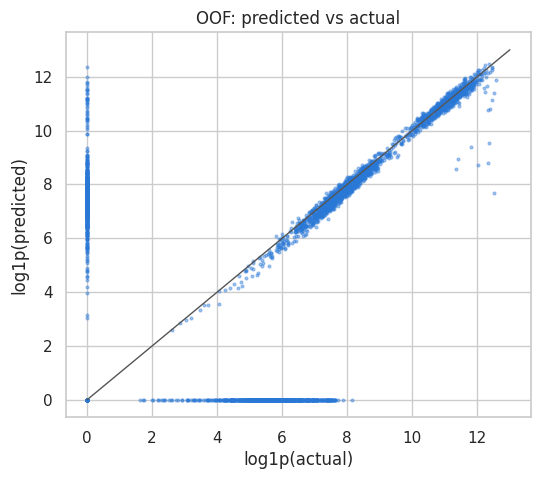

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
i = np.random.default_rng(0).choice(len(y), 5000, replace=False)
ax.scatter(np.log1p(y[i]), np.log1p(oof[i]), s=4, alpha=.4, color='#2a78d6'); ax.plot([0, 13], [0, 13], color='#555', lw=1)
ax.set(xlabel='log1p(actual)', ylabel='log1p(predicted)', title='OOF: predicted vs actual'); plt.show()

## 5. Submission
Writes `task3` into `../submission.csv` and keeps the other columns. If that file doesn't exist yet, it starts from `sample_submission.csv`. On Kaggle the file goes to `/kaggle/working/submission.csv`, starting from our best `submission.csv` if it is attached as a dataset (otherwise from `sample_submission.csv`).

In [10]:
import os
pred_out = pred.round(2)
print('exact zeros in test predictions:', (pred_out == 0).mean().round(3), '| quantiles:', np.percentile(pred_out, [50, 95, 99]).round(0))
pd.DataFrame({ID: test[ID], TARGET: pred_out}).to_csv(f'{OUT_DIR}/submission_task3.csv', index=False)

# Full submission: locally ../submission.csv; on Kaggle our best submission.csv if it is attached as a dataset,
# otherwise the competition's sample_submission.csv (then only this task's column is real)
if ON_KAGGLE:
    full = glob.glob('/kaggle/input/**/submission.csv', recursive=True)
    SUB = full[0] if full else glob.glob('/kaggle/input/**/sample_submission.csv', recursive=True)[0]
    OUT = f'{OUT_DIR}/submission.csv'
else:
    SUB = '../submission.csv' if os.path.exists('../submission.csv') else '../sample_submission.csv'
    OUT = '../submission.csv'
sub = pd.read_csv(SUB)
assert len(sub) == len(test), 'row count mismatch'
sub['task3'] = pred_out   # assumes row i of the submission = row i of test.csv
sub.to_csv(OUT, index=False)
print(f'updated {OUT} from {SUB}'); sub.head()

exact zeros in test predictions: 0.499 | quantiles: [1.70000e+01 7.56230e+04 1.34012e+05]
updated /kaggle/working/submission.csv from /kaggle/input/competitions/player-intelligence-system-cpe-342-ml/cpe342-kaggle-main/sample_submission.csv


,id,task1,task2,task3,task4,task5
0,ANS00001,1.0,2.0,0.00,0.0,1.0
1,ANS00002,0.0,1.0,2221.79,1.0,1.0
2,ANS00003,1.0,3.0,0.00,2.0,0.0
3,ANS00004,0.0,2.0,0.00,0.0,1.0
4,ANS00005,NaN,NaN,0.00,NaN,NaN
